# Yield Curve Regimes & Equity Positioning
## Week 5: How each sector performs in each regime

**Research question:** How have U.S. stock sectors performed in each yield-curve environment since 1976, and what does today’s environment suggest about which sectors are best positioned?

Last week you looked at the **whole market** after each regime. This week you look at **all 12 sectors**, which is the first half of the research question. You will:
1. Measure each sector’s average return in the month after each regime label.
2. Compare each sector with the market (its **excess return**) and count how often it beat the market (its **hit rate**).
3. See which results stand out from luck, then draw everything as one **heatmap**.
4. Check your four Week 2 guesses against the data.

**How to run it:** upload it to [Google Colab](https://colab.research.google.com) (File → Upload notebook), then **Runtime → Run all**. It loads `regime_next_month_returns.csv`, your Week 4 output, from your GitHub repository.

### 1. Load your paired dataset
**What this does:** reads the Week 4 file. Each row is one month’s returns next to the regime label that was known at the start of that month, so nothing here uses information from the future.

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle

GITHUB_CSV = "https://raw.githubusercontent.com/caden-smalls-greenwood/yield-curve-regimes/main/regime_next_month_returns.csv"
LOCAL_CSV  = Path("regime_next_month_returns.csv")
DATA = Path("data");    DATA.mkdir(exist_ok=True)
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

def load_dataset():
    if LOCAL_CSV.exists():
        print("Using the regime_next_month_returns.csv already in this folder.")
        return pd.read_csv(LOCAL_CSV)
    try:
        r = requests.get(GITHUB_CSV, timeout=30)
        r.raise_for_status()
        print("Loaded regime_next_month_returns.csv from your GitHub repository.")
        return pd.read_csv(io.StringIO(r.text))
    except requests.RequestException as e:
        print(f"Couldn't reach GitHub ({type(e).__name__}). Click 'Choose Files' and pick regime_next_month_returns.csv.")
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError("Put regime_next_month_returns.csv in this notebook's folder and run this cell again.")
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

raw = load_dataset()
paired = raw.set_index(pd.PeriodIndex(raw["month"], freq="M")).drop(columns="month")

SECTORS = ["Nondurables", "Durables", "Manufacturing", "Energy", "Chemicals", "Tech",
           "Telecom", "Utilities", "Retail", "Healthcare", "Finance", "Other"]
REGIMES = ["Bull steepener", "Bear steepener", "Bull flattener", "Bear flattener"]
COUNTS = paired["regime_known"].value_counts().reindex(REGIMES)

print(f"{len(paired)} paired months, {paired.index.min()} to {paired.index.max()}\n")
for regime, n in COUNTS.items():
    print(f"  {regime:15s} {n:>4} months")

Using the regime_next_month_returns.csv already in this folder.
599 paired months, 1976-10 to 2026-08

  Bull steepener   133 months
  Bear steepener   136 months
  Bull flattener   156 months
  Bear flattener   174 months


### 2. The three measures, in plain words
For every sector in every regime, the notebook works out:

| Measure | What it means | Why it matters |
|---|---|---|
| **Average return** | The sector’s average return in the month after the label | The raw number, but it mixes the sector with the whole market’s mood |
| **Excess return** | The sector’s return **minus the market’s**, averaged | A portfolio manager deciding to overweight or underweight a sector cares about beating the market, not just going up |
| **Hit rate** | The % of months the sector beat the market | Shows consistency. One huge month can drag an average up, but it only counts once in the hit rate |

**Why excess return is the main one:** in a bear flattener almost every sector has a lower average return, because the whole market does worse. That tells you about the market, not the sector. Subtracting the market takes that out, so you see which sectors did **better or worse than the market** in that environment.

**The ± range and the t-stat.** Just like Week 4, each average has a “± range” (one standard error) showing how much luck could move it. The **t-stat** is the average divided by its ± range: how many ± ranges the result sits away from zero.
- Between −2 and +2: could easily be luck.
- Beyond ±2: stands out from the noise. This is the usual bar in finance research.

In [2]:
by = paired["regime_known"]
excess = paired[SECTORS].sub(paired["Market"], axis=0)        # sector minus market, every month

avg_return = paired[SECTORS].groupby(by).mean().T[REGIMES] * 100
market_row = (paired.groupby(by)["Market"].mean()[REGIMES] * 100).rename("Market (for reference)")

avg_excess = excess.groupby(by).mean().T[REGIMES] * 100
avg_excess["All months"] = excess.mean() * 100

hit_rate = (excess > 0).groupby(by).mean().T[REGIMES] * 100
hit_rate["All months"] = (excess > 0).mean() * 100

plus_minus = excess.groupby(by).std().T[REGIMES] / np.sqrt(COUNTS) * 100   # one standard error
t_stat = avg_excess[REGIMES] / plus_minus

for table in (avg_return, avg_excess, hit_rate, plus_minus, t_stat):
    table.index.name, table.columns.name = "Sector", None
print("Done: average returns, excess returns, hit rates and t-stats for 12 sectors x 4 regimes.")

Done: average returns, excess returns, hit rates and t-stats for 12 sectors x 4 regimes.


### 3. Table 1: average next-month return (% per month)
Read across a row to see how one sector did in each environment. The top row is the market, for comparison. Notice that most of the **bear flattener** column is lower than the others: that is the whole market doing worse, which is why Table 2 subtracts it.

In [3]:
pd.concat([market_row.to_frame().T, avg_return]).round(2)

,Bull steepener,Bear steepener,Bull flattener,Bear flattener
Market (for reference),1.32,0.97,1.21,0.79
Nondurables,1.23,1.00,1.23,0.94
Durables,1.81,2.00,1.57,-0.42
Manufacturing,1.22,1.52,1.15,0.71
Energy,0.93,0.95,1.04,1.44
Chemicals,1.11,0.88,1.19,0.59
Tech,1.67,0.79,1.53,0.89
Telecom,0.66,0.86,1.35,0.68
Utilities,1.11,1.08,1.03,0.64
Retail,1.73,1.02,1.38,0.62


### 4. Table 2: excess return vs. the market (% per month)
**This is the main result of the project so far.** Positive = the sector beat the market in the month after that label; negative = it lagged.

The **All months** column is each sector’s usual gap with the market across all 599 months. Compare a regime’s number with it: a sector that beats the market by a little in every regime isn’t special in any one of them.

In [4]:
avg_excess.round(2)

,Bull steepener,Bear steepener,Bull flattener,Bear flattener,All months
Sector,,,,,
Nondurables,-0.09,0.04,0.02,0.15,0.03
Durables,0.49,1.04,0.36,-1.21,0.09
Manufacturing,-0.09,0.55,-0.06,-0.09,0.06
Energy,-0.38,-0.01,-0.17,0.65,0.06
Chemicals,-0.21,-0.09,-0.02,-0.20,-0.13
Tech,0.35,-0.17,0.32,0.10,0.15
Telecom,-0.66,-0.10,0.14,-0.11,-0.17
Utilities,-0.21,0.11,-0.18,-0.15,-0.11
Retail,0.41,0.06,0.17,-0.17,0.10


### 5. Table 3: hit rate (% of months the sector beat the market)
Around 50% is a coin flip. Look for numbers well above or below 50, and for cells where the hit rate and the average from Table 2 disagree.

In [5]:
hit_rate.round(0).astype(int)

,Bull steepener,Bear steepener,Bull flattener,Bear flattener,All months
Sector,,,,,
Nondurables,47,51,54,55,52
Durables,47,56,54,34,47
Manufacturing,52,59,50,49,52
Energy,48,44,51,53,49
Chemicals,45,46,48,48,47
Tech,51,51,54,47,51
Telecom,43,46,49,49,47
Utilities,48,43,49,50,48
Retail,56,52,54,47,52


### 6. Which results stand out from luck?
This lists every sector-regime pair with a t-stat beyond ±2.

**One important warning:** you are testing 48 cells at once (12 sectors × 4 regimes). Even if regimes didn’t matter at all, about 1 cell in 22 would cross ±2 by luck. That is **data snooping**, trap #4 from Week 3. So a standout is something to investigate, not proof.

In [6]:
cells_t = pd.Series({(s, r): t_stat.loc[s, r] for s in SECTORS for r in REGIMES})   # one entry per square
standouts = cells_t[cells_t.abs() >= 2].sort_values(key=lambda s: s.abs(), ascending=False)

print("Results at least 2 ± ranges from zero:\n")
for (sector, regime), t in standouts.items():
    print(f"  {sector:13s} after a {regime.lower():15s} excess {avg_excess.loc[sector, regime]:+.2f}% per month, "
          f"beat the market in {hit_rate.loc[sector, regime]:.0f}% of months, t-stat {t:+.1f}")
print(f"\n{len(standouts)} of {cells_t.size} cells cross ±2. "
      f"If regimes didn't matter at all, luck alone would give about {cells_t.size * 0.0455:.0f}.")

Results at least 2 ± ranges from zero:

  Durables      after a bear flattener  excess -1.21% per month, beat the market in 34% of months, t-stat -3.3
  Manufacturing after a bear steepener  excess +0.55% per month, beat the market in 59% of months, t-stat +2.5
  Other         after a bear flattener  excess -0.33% per month, beat the market in 44% of months, t-stat -2.5
  Telecom       after a bull steepener  excess -0.66% per month, beat the market in 43% of months, t-stat -2.2

4 of 48 cells cross ±2. If regimes didn't matter at all, luck alone would give about 2.


### 7. The heatmap: every sector in every regime on one chart
Each square is a number from Table 2. **Blue** = beat the market, **red** = lagged it, gray = about even. Boxed squares are the standouts from step 6.

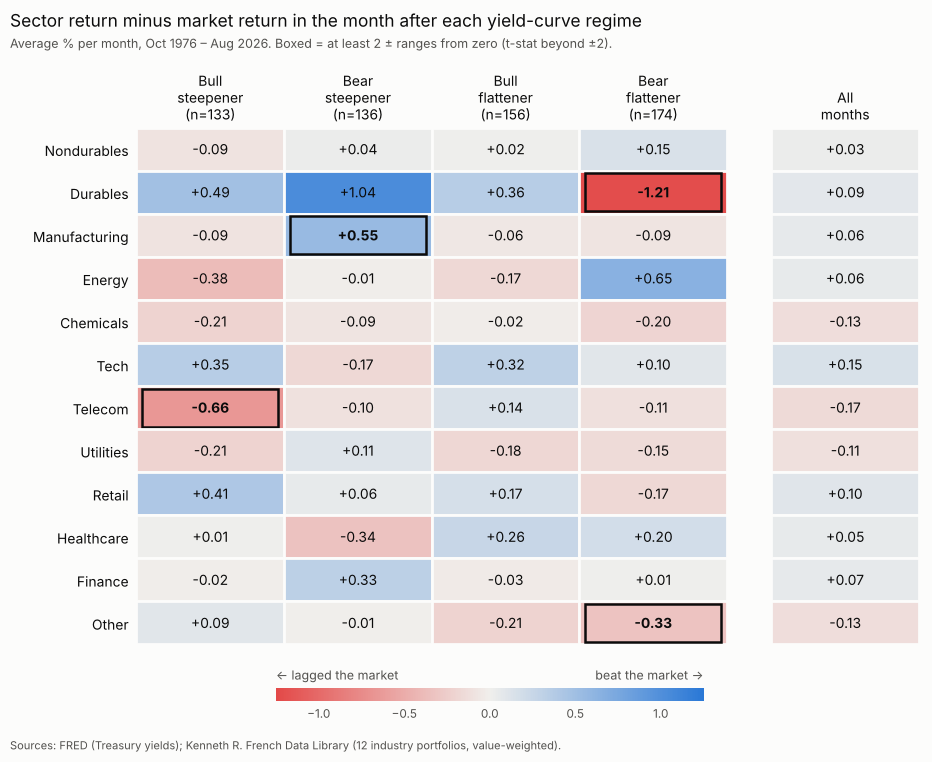

In [7]:
INK, MUTED, BG = "#0b0b0b", "#52514e", "#fcfcfb"
cmap = LinearSegmentedColormap.from_list("lag_to_beat", ["#e34948", "#f0efec", "#2a78d6"])
cols = REGIMES + ["All months"]
vals = avg_excess[cols]
lim = np.ceil(np.abs(vals.values).max() * 4) / 4              # same color scale both ways, rounded up to 0.25
norm = Normalize(-lim, lim)
xs = [0, 1, 2, 3, 4.3]                                        # small gap before the "All months" column

fig, ax = plt.subplots(figsize=(9.5, 7.6), facecolor=BG)
ax.set_facecolor(BG)
for i, sector in enumerate(vals.index):
    for j, col in enumerate(cols):
        v = vals.loc[sector, col]
        ax.add_patch(Rectangle((xs[j], i), 1, 1, facecolor=cmap(norm(v)), edgecolor=BG, linewidth=2))
        strong = col in REGIMES and abs(t_stat.loc[sector, col]) >= 2
        if strong:
            ax.add_patch(Rectangle((xs[j] + 0.04, i + 0.06), 0.92, 0.88, fill=False, edgecolor=INK, linewidth=1.8))
        ax.text(xs[j] + 0.5, i + 0.5, f"{v:+.2f}", ha="center", va="center", fontsize=10,
                color=INK, fontweight="bold" if strong else "normal")

ax.set_xlim(-0.02, xs[-1] + 1.02)
ax.set_ylim(len(vals), 0)
ax.xaxis.tick_top()
ax.set_xticks([x + 0.5 for x in xs])
ax.set_xticklabels([f"{c.replace(' ', chr(10))}\n(n={COUNTS[c]})" for c in REGIMES] + ["All\nmonths"], color=INK, fontsize=10)
ax.set_yticks([i + 0.5 for i in range(len(vals))])
ax.set_yticklabels(vals.index, color=INK, fontsize=10)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)

fig.suptitle("Sector return minus market return in the month after each yield-curve regime",
             x=0.02, ha="left", color=INK, fontsize=12.5, y=0.985)
fig.text(0.02, 0.935, "Average % per month, Oct 1976 – Aug 2026. Boxed = at least 2 ± ranges from zero (t-stat beyond ±2).",
         color=MUTED, fontsize=9)
cax = fig.add_axes([0.30, 0.075, 0.45, 0.018])
bar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
bar.outline.set_visible(False)
bar.ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
cax.text(0, 1.6, "← lagged the market", transform=cax.transAxes, ha="left", color=MUTED, fontsize=9)
cax.text(1, 1.6, "beat the market →", transform=cax.transAxes, ha="right", color=MUTED, fontsize=9)
fig.text(0.02, 0.012, "Sources: FRED (Treasury yields); Kenneth R. French Data Library (12 industry portfolios, value-weighted).",
         color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.15, right=0.98, top=0.83, bottom=0.15)
fig.savefig(FIGS / "sector_heatmap.png", dpi=200, facecolor=BG)
plt.show()

### 8. Check your Week 2 guesses
In Week 2 you made four predictions before seeing any returns. This cell tests each one with the same rule for all of them:
- **Supported:** the result goes your way and the t-stat is beyond 2.
- **Leans your way:** right direction, but within the noise.
- **No real difference:** too close to zero to say.
- **Not supported:** it went the other way.

Being wrong here is normal and fine. Writing guesses down **before** looking, then reporting honestly, is exactly what keeps research from being data snooping.

In [8]:
HYPOTHESES = [   # (your Week 2 guess, regime, sectors, which way you expected vs. the market)
    ("Finance does well in bull steepeners",        "Bull steepener", ["Finance"],                            "beat"),
    ("Utilities are hurt in bear steepeners",       "Bear steepener", ["Utilities"],                          "lag"),
    ("Defensive sectors hold up in bull flatteners", "Bull flattener", ["Healthcare", "Nondurables", "Utilities"], "beat"),
    ("Tech does worst in bear flatteners",           "Bear flattener", ["Tech"],                               "lag"),
]

def verdict(t, expected):
    t = t if expected == "beat" else -t       # flip so that "your way" is always positive
    if t >= 2:    return "Supported"
    if t >= 0.5:  return "Leans your way, but within the noise"
    if t > -0.5:  return "No real difference from the market"
    return "Not supported: it went the other way"

for guess, regime, sectors, expected in HYPOTHESES:
    col = avg_excess[regime]
    rank = col.rank(ascending=False).astype(int)
    print(f"Week 2 guess: {guess}")
    for s in sectors:
        print(f"   {s:12s} excess {col[s]:+.2f}%/month | beat the market {hit_rate.loc[s, regime]:.0f}% of months | "
              f"t-stat {t_stat.loc[s, regime]:+.1f} | rank {rank[s]} of 12  →  {verdict(t_stat.loc[s, regime], expected)}")
    print(f"   In this regime the best sector was {col.idxmax()} ({col.max():+.2f}%) and the worst was {col.idxmin()} ({col.min():+.2f}%)\n")

Week 2 guess: Finance does well in bull steepeners
   Finance      excess -0.02%/month | beat the market 54% of months | t-stat -0.1 | rank 6 of 12  →  No real difference from the market
   In this regime the best sector was Durables (+0.49%) and the worst was Telecom (-0.66%)

Week 2 guess: Utilities are hurt in bear steepeners
   Utilities    excess +0.11%/month | beat the market 43% of months | t-stat +0.3 | rank 4 of 12  →  No real difference from the market
   In this regime the best sector was Durables (+1.04%) and the worst was Healthcare (-0.34%)

Week 2 guess: Defensive sectors hold up in bull flatteners
   Healthcare   excess +0.26%/month | beat the market 46% of months | t-stat +1.1 | rank 3 of 12  →  Leans your way, but within the noise
   Nondurables  excess +0.02%/month | beat the market 54% of months | t-stat +0.1 | rank 6 of 12  →  No real difference from the market
   Utilities    excess -0.18%/month | beat the market 49% of months | t-stat -0.5 | rank 11 of 12  →  Not

### 9. Save the results
This writes `data/sector_results_by_regime.csv`: one row per regime and sector with every number from this week. Upload it, `sector_heatmap.png` and this notebook to your GitHub repository.

In [9]:
rows = []
for regime in REGIMES:
    for s in SECTORS:
        rows.append({"regime": regime, "sector": s, "months": int(COUNTS[regime]),
                     "avg_return_pct": avg_return.loc[s, regime], "excess_vs_market_pct": avg_excess.loc[s, regime],
                     "plus_minus_pct": plus_minus.loc[s, regime], "t_stat": t_stat.loc[s, regime],
                     "hit_rate_pct": hit_rate.loc[s, regime]})
results = pd.DataFrame(rows).round(2)
results.to_csv(DATA / "sector_results_by_regime.csv", index=False)
print("Saved", DATA / "sector_results_by_regime.csv", "-", len(results), "rows")

try:                                   # only works inside Google Colab
    from google.colab import files
    files.download(str(DATA / "sector_results_by_regime.csv"))
    files.download(str(FIGS / "sector_heatmap.png"))
except ImportError:
    print("Not running in Colab: find the files in the data/ and figures/ folders.")

Saved data/sector_results_by_regime.csv - 48 rows
Not running in Colab: find the files in the data/ and figures/ folders.


### 10. Week 5 study questions
1. Why does the project compare each sector with the market (excess return) instead of just using its average return? Use the bear flattener column of Tables 1 and 2 as your example.
2. Which result stands out the most in step 6? Say what it means in plain words, and give an economic reason it could make sense.
3. Go through your four Week 2 guesses. For each one, was it supported, leaning, no real difference, or not supported? Which result surprised you most?
4. There are 48 cells in the heatmap. If regimes didn’t matter at all, about how many would cross ±2 by luck? How many did, and what does that mean for how much you trust the standouts?
5. Energy after a bear flattener has a high average excess return but a hit rate near 50%. How can both be true, and why does it matter for an investor?
6. The latest label in your data (September 2026) is a **bear steepener**. Using only this week’s results, which two sectors look best positioned and which two look worst? What would you want to check before trusting that call?

**Next (Week 6):** robustness checks. Do the standouts hold up before and after 2000, and are any of them driven by just a few huge months?